<a href="https://colab.research.google.com/github/Shahnazain/AIML-Lab/blob/main/lab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Load the Dataset and Display Basic Information

The Loan Prediction Dataset is loaded into the Google Colab notebook using the Pandas library. The basic information of the dataset is displayed to understand its structure, attributes, non-null values, and data types.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

In [ ]:
import pandas as pd

df = pd.read_csv("/content/train_u6lujuX_CVtuZ9i.csv")

original_df = df.copy()

print("Basic Information of the Dataset:")
df.info()

## 2. Identify Rows, Columns, Data Types, and Missing Values

The structure of the dataset is examined by identifying the number of rows and columns, data types of each attribute, and missing values present in each column.

In [ ]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])
print("Data Types of Each Column:")
print(df.dtypes)

print("Missing Values in Each Column:")
print(df.isnull().sum())

## 3. Exploratory Data Inspection

The dataset is inspected by displaying the first, last, and randomly selected records to understand its structure and contents.

In [ ]:
print("First 5 Records of the Dataset:")
display(df.head())
print("Last 5 Records of the Dataset:")
display(df.tail())

print("5 Randomly Selected Records:")
display(df.sample(5, random_state=42))

## 4. Detect and Handle Missing Values

Missing values are detected using the `isnull()` function. Appropriate imputation techniques are applied based on the type and nature of each attribute.

In [ ]:
print("Missing Values Before Handling:")
print(df.isnull().sum())

categorical_columns = [
    'Gender',
    'Married',
    'Dependents',
    'Self_Employed'
]

for column in categorical_columns:
    df[column] = df[column].fillna(
        df[column].mode()[0]
    )

df['LoanAmount'] = df['LoanAmount'].fillna(
    df['LoanAmount'].median()
)

df['Loan_Amount_Term'] = df['Loan_Amount_Term'].fillna(
    df['Loan_Amount_Term'].mode()[0]
)

df['Credit_History'] = df['Credit_History'].fillna(
    df['Credit_History'].mode()[0]
)

print("Missing Values After Handling:")
print(df.isnull().sum())

## 5. Identify and Remove Duplicate Records

Duplicate records are identified using the `duplicated()` function and removed using the `drop_duplicates()` function to avoid redundant data in the dataset.

In [ ]:
duplicate_count =  df.duplicated().sum()

print("Number of Duplicate Records:",  duplicate_count)
df_duplicates = pd.concat([df, df.iloc[:3]], ignore_index=True)

print("Number of Rows Before Adding Duplicates:", len(df))
print("Number of Rows After Adding Duplicates:", len(df_duplicates))

duplicate_records = df_duplicates[df_duplicates.duplicated()]

print("Duplicate Records:")
display(duplicate_records)

print("Number of Duplicate Records:",
      df_duplicates.duplicated().sum())

df_duplicates = df_duplicates.drop_duplicates()
print("Duplicate records removed successfully")

print("Number of Duplicate Records After Removal:",
      df_duplicates.duplicated().sum())


print("Number of Rows After Removing Duplicates:",
      len(df_duplicates))

df = df_duplicates.copy()


## 6. Detect Outliers Using IQR and Visualize Using Box Plots

Outliers in numerical attributes are detected using the Interquartile Range (IQR) method and visualized using box plots.

In [ ]:
import matplotlib.pyplot as plt

numerical_columns = [
    'ApplicantIncome',
    'CoapplicantIncome',
    'LoanAmount'
]

for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(f"{column}: {len(outliers)} outliers")

for column in numerical_columns:
    plt.figure(figsize=(8, 4))
    plt.boxplot(df[column].dropna(), vert=False)
    plt.title(f"Box Plot of {column}")
    plt.xlabel(column)
    plt.show()

## 7. Handle Outliers

Outliers are handled using the IQR capping technique. Values below the lower bound are replaced with the lower bound, while values above the upper bound are replaced with the upper bound.

In [ ]:
numerical_columns = [
    'ApplicantIncome',
    'CoapplicantIncome',
    'LoanAmount'
]
for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df[column] = df[column].clip(
        lower=lower_bound,
        upper=upper_bound
    )

print("Outliers handled using IQR capping.")


for column in numerical_columns:
    plt.figure(figsize=(8, 4))
    plt.boxplot(df[column], vert=False)
    plt.title(f"Box Plot of {column} After Outlier Handling")
    plt.xlabel(column)
    plt.show()

## 8. Convert Categorical Variables into Numerical Form

Categorical variables are converted into numerical form using Label Encoding and One-Hot Encoding.

In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

df['Loan_Status'] = label_encoder.fit_transform(
    df['Loan_Status']
)

print("Loan_Status after Label Encoding:")
print(df['Loan_Status'].head())

df = pd.get_dummies(
    df,
    columns=[
        'Gender',
        'Married',
        'Dependents',
        'Education',
        'Self_Employed',
        'Property_Area'
    ],
    drop_first=True,
    dtype=int
)

print("Dataset After One-Hot Encoding:")
display(df.head())

## 9. Feature Scaling

Feature scaling is performed using Min-Max Normalization and Standardization (Z-score Scaling).


In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaling_columns = [
    'ApplicantIncome',
    'CoapplicantIncome',
    'LoanAmount',
    'Loan_Amount_Term'
]

minmax_scaler = MinMaxScaler()

df_minmax = df.copy()

df_minmax[scaling_columns] = minmax_scaler.fit_transform(
    df_minmax[scaling_columns]
)

print("Min-Max Normalized Data:")
display(df_minmax[scaling_columns].head())

from sklearn.preprocessing import StandardScaler

standard_scaler = StandardScaler()

df_standardized = df.copy()

df_standardized[scaling_columns] = standard_scaler.fit_transform(
    df_standardized[scaling_columns]
)

print("Standardized Data:")
display(df_standardized[scaling_columns].head())

## 10. Feature Selection Using Correlation Analysis

Correlation analysis is used to identify numerical attributes that have a strong relationship with the target variable Loan_Status.

In [ ]:
# Convert Loan_Status into numerical form if it is still categorical
if df['Loan_Status'].dtype == 'object':
    df['Loan_Status'] = df['Loan_Status'].map({
        'N': 0,
        'Y': 1
    })

# Select numerical columns
numeric_df = df.select_dtypes(include='number')

print("Numerical Columns:")
print(numeric_df.columns)

correlation_with_target = numeric_df.corr()['Loan_Status'].sort_values(
    ascending=False
)

print("Correlation with Loan_Status:")
print(correlation_with_target)

relevant_features = correlation_with_target[
    abs(correlation_with_target) > 0.1
]

print("Relevant Features Based on Correlation:")
print(relevant_features)

## 11. Correlation Matrix and Heatmap

A correlation matrix and heatmap are generated to study the relationships between numerical attributes in the dataset.

In [ ]:
import seaborn as sns

correlation_matrix = numeric_df.corr()

print("Correlation Matrix:")
display(correlation_matrix)

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

## 12. Feature Engineering

New features are created from existing attributes to provide additional meaningful information for data analysis.

In [ ]:
df['TotalIncome'] = (
    df['ApplicantIncome'] +
    df['CoapplicantIncome']
)

df['IncomeToLoanRatio'] = (
    df['TotalIncome'] / df['LoanAmount']
)

print("Newly Engineered Features:")
display(
    df[
        [
            'ApplicantIncome',
            'CoapplicantIncome',
            'LoanAmount',
            'TotalIncome',
            'IncomeToLoanRatio'
        ]
    ].head()
)

## 13. Data Type Conversion

Data types are converted wherever necessary to ensure that attributes are represented using appropriate data types.

In [ ]:
print("Data Types Before Conversion:")
print(df[['Credit_History', 'Loan_Amount_Term']].dtypes)

df['Credit_History'] = df['Credit_History'].astype(int)
df['Loan_Amount_Term'] = df['Loan_Amount_Term'].astype(int)

print("Data Types After Conversion:")
print(df[['Credit_History', 'Loan_Amount_Term']].dtypes)

## 14. Handle Inconsistent and Noisy Data

The dataset is checked for inconsistent column names, infinite values, and invalid numerical values. Suitable cleaning techniques are applied.

In [ ]:
import numpy as np

df.columns = df.columns.str.strip()

df.replace([np.inf, -np.inf], np.nan, inplace=True)

print("Infinite values replaced with NaN.")
print("Number of missing values after noise check:")
print(df.isnull().sum())

import numpy as np

df.columns = df.columns.str.strip()

df.replace([np.inf, -np.inf], np.nan, inplace=True)

print("Infinite values replaced with NaN.")
print("Number of missing values after noise check:")
print(df.isnull().sum())

## 15. Split the Dataset into Training and Testing Sets

The dataset is divided into training and testing sets using Scikit-learn. The training set is used for model learning, while the testing set is reserved for evaluation.

In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Loan_Status', 'Loan_ID'])
y = df['Loan_Status']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Feature Set Shape:", X_train.shape)
print("Testing Feature Set Shape:", X_test.shape)
print("Training Target Set Shape:", y_train.shape)
print("Testing Target Set Shape:", y_test.shape)

## 16. Data Balancing Using SMOTE

The class distribution of the target variable is examined. SMOTE is applied to the training dataset to balance the minority and majority classes.

In [ ]:
print("Class Distribution Before SMOTE:")
print(y_train.value_counts())

from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train,
    y_train
)

print("Class Distribution After SMOTE:")
print(y_train_balanced.value_counts())

plt.figure(figsize=(6, 4))
y_train.value_counts().sort_index().plot(kind='bar')
plt.title("Class Distribution Before SMOTE")
plt.xlabel("Loan Status")
plt.ylabel("Number of Records")
plt.show()

plt.figure(figsize=(6, 4))
y_train_balanced.value_counts().sort_index().plot(kind='bar')
plt.title("Class Distribution After SMOTE")
plt.xlabel("Loan Status")
plt.ylabel("Number of Records")
plt.show()

## 17. Distribution of Numerical Features Before and After Preprocessing

The distributions of selected numerical attributes are visualized before and after preprocessing using histograms.

In [ ]:
distribution_columns = [
    'ApplicantIncome',
    'CoapplicantIncome',
    'LoanAmount'
]

for column in distribution_columns:
    plt.figure(figsize=(8, 4))
    plt.hist(
        original_df[column].dropna(),
        bins=30
    )
    plt.title(f"{column} Distribution Before Preprocessing")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.show()

for column in distribution_columns:
    plt.figure(figsize=(8, 4))
    plt.hist(
        df[column].dropna(),
        bins=30
    )
    plt.title(f"{column} Distribution After Preprocessing")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.show()

## 18. Comparison Before and After Preprocessing

The original and preprocessed datasets are compared based on their dimensions, missing values, duplicate records, and number of attributes.

In [ ]:
comparison = pd.DataFrame({
    'Measure': [
        'Number of Rows',
        'Number of Columns',
        'Missing Values',
        'Duplicate Records'
    ],
    'Before Preprocessing': [
        original_df.shape[0],
        original_df.shape[1],
        original_df.isnull().sum().sum(),
        original_df.duplicated().sum()
    ],
    'After Preprocessing': [
        df.shape[0],
        df.shape[1],
        df.isnull().sum().sum(),
        df.duplicated().sum()
    ]
})

display(comparison)

print("Dataset Before Preprocessing:")
display(original_df.head())

print("Dataset After Preprocessing:")
display(df.head())

## 19. Save the Cleaned and Preprocessed Dataset

The final cleaned and preprocessed dataset is saved as a new CSV file for future analysis and machine learning tasks.

In [ ]:
df.to_csv(
    "cleaned_loan_prediction_dataset.csv",
    index=False
)

print("Cleaned dataset saved successfully.")

saved_df = pd.read_csv(
    "cleaned_loan_prediction_dataset.csv"
)

print("Saved Dataset Shape:", saved_df.shape)
display(saved_df.head())

## 20. Documentation of Data Preprocessing Steps

The following preprocessing steps were performed in this notebook:

1. The Loan Prediction dataset was loaded using the Pandas library.
2. The number of rows, columns, data types, and missing values were identified.
3. The first, last, and randomly selected records were inspected.
4. Missing values were handled using median and mode imputation techniques.
5. Duplicate records were identified and removed.
6. Outliers were detected using the IQR method and visualized using box plots.
7. Outliers were handled using IQR-based capping.
8. Categorical variables were converted into numerical form using Label Encoding and One-Hot Encoding.
9. Min-Max Normalization and Standardization were demonstrated for numerical attributes.
10. Relevant attributes were identified using correlation analysis.
11. A correlation matrix and heatmap were generated and interpreted.
12. New attributes were created using feature engineering.
13. Suitable attributes were converted into appropriate data types.
14. Inconsistent and noisy data were identified and cleaned.
15. The dataset was divided into training and testing sets.
16. SMOTE was applied to balance the target classes in the training dataset.
17. Numerical feature distributions were visualized before and after preprocessing.
18. The dataset was compared before and after preprocessing.
19. The cleaned and preprocessed dataset was saved as a new CSV file.




**LINEAR REGRESSION**

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

df = pd.read_csv(
    "/content/sample_data/california_housing_test.csv"
)

print("Dataset Shape:", df.shape)

display(df.head())


Dataset Shape: (3000, 9)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-122.05,37.37,27.0,3885.0,661.0,1537.0,606.0,6.6085,344700.0
1,-118.30,34.26,43.0,1510.0,310.0,809.0,277.0,3.5990,176500.0
2,-117.81,33.78,27.0,3589.0,507.0,1484.0,495.0,5.7934,270500.0
3,-118.36,33.82,28.0,67.0,15.0,49.0,11.0,6.1359,330000.0
4,-119.67,36.33,19.0,1241.0,244.0,850.0,237.0,2.9375,81700.0


In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           3000 non-null   float64
 1   latitude            3000 non-null   float64
 2   housing_median_age  3000 non-null   float64
 3   total_rooms         3000 non-null   float64
 4   total_bedrooms      3000 non-null   float64
 5   population          3000 non-null   float64
 6   households          3000 non-null   float64
 7   median_income       3000 non-null   float64
 8   median_house_value  3000 non-null   float64
dtypes: float64(9)
memory usage: 211.1 KB


In [ ]:
df.isnull().sum()


,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,0
population,0
households,0
median_income,0
median_house_value,0


In [ ]:
df.describe()


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,3000.000000,3000.00000,3000.000000,3000.000000,3000.000000,3000.000000,3000.00000,3000.000000,3000.00000
mean,-119.589200,35.63539,28.845333,2599.578667,529.950667,1402.798667,489.91200,3.807272,205846.27500
std,1.994936,2.12967,12.555396,2155.593332,415.654368,1030.543012,365.42271,1.854512,113119.68747
min,-124.180000,32.56000,1.000000,6.000000,2.000000,5.000000,2.00000,0.499900,22500.00000
25%,-121.810000,33.93000,18.000000,1401.000000,291.000000,780.000000,273.00000,2.544000,121200.00000
50%,-118.485000,34.27000,29.000000,2106.000000,437.000000,1155.000000,409.50000,3.487150,177650.00000
75%,-118.020000,37.69000,37.000000,3129.000000,636.000000,1742.750000,597.25000,4.656475,263975.00000
max,-114.490000,41.92000,52.000000,30450.000000,5419.000000,11935.000000,4930.00000,15.000100,500001.00000


**Simple linear regression**

Coefficient: 40940.61285055091
Intercept: 50847.821195044846
MAE: 60123.4795207441
MSE: 6355701945.134971
RMSE: 79722.65641042683
R2 Score: 0.4953198289574966


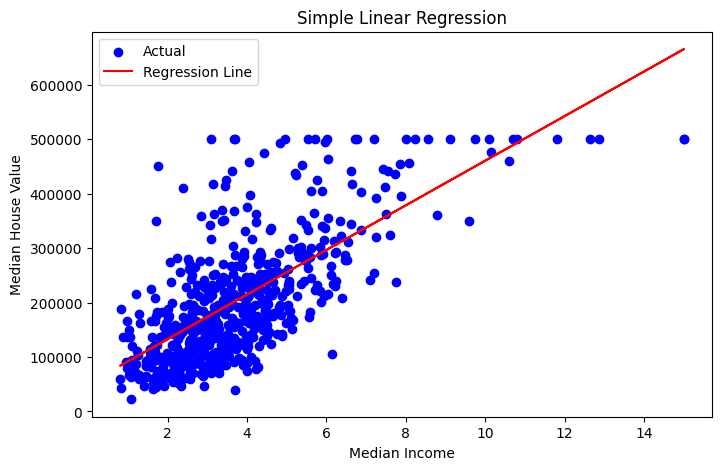

In [ ]:
X = df[['median_income']]

y = df['median_house_value']

#split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


simple_lr = LinearRegression()


simple_lr.fit(
    X_train,
    y_train
)

y_pred_simple = simple_lr.predict(
    X_test
)

print(
    "Coefficient:",
    simple_lr.coef_[0]
)

print(
    "Intercept:",
    simple_lr.intercept_
)

simple_mae = mean_absolute_error(
    y_test,
    y_pred_simple
)

simple_mse = mean_squared_error(
    y_test,
    y_pred_simple
)

simple_rmse = np.sqrt(simple_mse)

simple_r2 = r2_score(
    y_test,
    y_pred_simple
)


print("MAE:", simple_mae)
print("MSE:", simple_mse)
print("RMSE:", simple_rmse)
print("R2 Score:", simple_r2)


plt.figure(figsize=(8,5))

plt.scatter(
    X_test,
    y_test,
    color='blue',
    label="Actual"
)

plt.plot(
    X_test,
    y_pred_simple,
    color='red',
    label="Regression Line"
)

plt.xlabel("Median Income")
plt.ylabel("Median House Value")

plt.title(
    "Simple Linear Regression"
)

plt.legend()

plt.show()


**Multiple Linear Regression**

In [ ]:
X = df[
[
    'median_income',
    'housing_median_age',
    'total_rooms',
    'total_bedrooms',
    'population',
    'households',
    'latitude',
    'longitude'
]
]

y = df['median_house_value']
X = X.fillna(X.mean())


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


multiple_lr = LinearRegression()


multiple_lr.fit(
    X_train,
    y_train
)

y_pred_multiple = multiple_lr.predict(
    X_test
)


coefficients = pd.DataFrame(
    {
        "Feature": X.columns,
        "Coefficient": multiple_lr.coef_
    }
)

display(coefficients)


multiple_mae = mean_absolute_error(
    y_test,
    y_pred_multiple
)

multiple_mse = mean_squared_error(
    y_test,
    y_pred_multiple
)

multiple_rmse = np.sqrt(
    multiple_mse
)

multiple_r2 = r2_score(
    y_test,
    y_pred_multiple
)


print("MAE:", multiple_mae)
print("MSE:", multiple_mse)
print("RMSE:", multiple_rmse)
print("R2 Score:", multiple_r2)


comparison = pd.DataFrame(
    {
        "Model":
        [
            "Simple Linear Regression",
            "Multiple Linear Regression"
        ],

        "MAE":
        [
            simple_mae,
            multiple_mae
        ],

        "RMSE":
        [
            simple_rmse,
            multiple_rmse
        ],

        "R2 Score":
        [
            simple_r2,
            multiple_r2
        ]
    }
)

display(comparison)
results = pd.DataFrame(
    {
        "Actual Price": y_test,
        "Predicted Price": y_pred_multiple
    }
)

display(results.head(10))


,Feature,Coefficient
0,median_income,39548.136989
1,housing_median_age,1147.116661
2,total_rooms,-7.886314
3,total_bedrooms,98.527564
4,population,-40.504835
5,households,61.434944
6,latitude,-43358.303029
7,longitude,-44009.947260


MAE: 49554.276208268224
MSE: 4586505886.681246
RMSE: 67723.74684467219
R2 Score: 0.635804416985041


,Model,MAE,RMSE,R2 Score
0,Simple Linear Regression,60123.479521,79722.656410,0.495320
1,Multiple Linear Regression,49554.276208,67723.746845,0.635804


,Actual Price,Predicted Price
1801,119400.0,126565.069443
1190,133600.0,145859.800832
1817,173600.0,247176.001173
251,218600.0,207110.679931
2505,276700.0,194794.790395
1117,146800.0,175428.699974
1411,166300.0,229747.207280
2113,197200.0,163606.508357
408,162500.0,69564.074478
2579,287800.0,197037.575346
